# Industry Project: Call-Centre Volume Forecasting for Staffing (Production-Style)

> **Who is this notebook for?** A beginner who has seen ARIMA / exponential smoothing in theory and wants to see how a
> real **workforce-management (WFM)** team uses classical statistical models to decide **how many people to schedule**.
> Every step is explained in plain English and almost every line of code is commented.

---

### How this notebook is different from the others in `04_Forecasting/`

| `01_time_series_basics.ipynb`, `02_classical_methods.ipynb`, `09_probabilistic_forecasting.ipynb` | This notebook |
|---|---|
| Explain STL, ETS, SARIMA, prediction intervals on textbook series | Uses them on **hourly** data with **two seasonalities** (daily and weekly) and **holidays** |
| One train/test split | **Rolling-origin backtest** with 8 forecast dates, compared with the baselines WFM tools use |
| Intervals are drawn, rarely checked | Intervals are **checked for coverage** and re-calibrated when they lie |
| The forecast is the end product | The forecast is turned into **number of agents per hour** with the **Erlang C** formula, and judged by **service level and cost** |
| - | Daily vs hourly forecasts **reconciled** so the numbers add up; saving, a forecast function, tests |

---

### The business problem

You work in the WFM team of a utility company's customer-service line, open **24/7**.

- The contact centre promises a **service level of 80/20**: at least **80% of calls answered within 20 seconds**.
- An average call lasts **6 minutes** (Average Handle Time, AHT = 360 s).
- An agent costs about **$32 per hour**, and only ~70% of paid time is spent on the phones (breaks, training, meetings:
  this 30% is called **shrinkage**).
- Schedules are published **two weeks ahead**, so every second Tuesday we need an **hourly forecast for the next 14 days**.

Too few agents: customers wait, the service level is missed, complaints and regulator penalties follow.
Too many agents: the company pays people to wait for calls. **Success = meet 80/20 in as many hours as possible with as
few paid agent-hours as possible.** A better forecast is only worth something if it improves that trade-off.

### Workflow
```
 ACD export -> clean (gaps, duplicates, incidents) -> validate -> look at seasonality (MSTL)
      -> baselines -> hourly MSTL+ETS  &  daily SARIMAX+holidays -> reconcile/combine
      -> rolling-origin backtest -> interval coverage -> Erlang C staffing -> $ and service level
      -> save -> forecast_and_staff() -> tests
```

### Table of Contents
1. Setup and config
2. Get the data: hourly call volumes and a holiday calendar
3. First look: two seasonalities and holidays
4. Clean the data: gaps, duplicates and incident spikes
5. Validate the data
6. Decompose the series with MSTL (multiple seasonality)
7. Backtesting design, baselines and metrics
8. Model A: hourly MSTL + exponential smoothing + holiday factors
9. Model B: daily SARIMAX with holiday regressors, split into hours
10. Reconciliation: make daily and hourly forecasts agree
11. Backtest results
12. Error analysis: holidays and hours of the day
13. Prediction intervals: are they honest?
14. From calls to agents: Erlang C
15. Does a better forecast give better staffing?
16. Save the configuration and a forecast-and-staff function
17. Automated tests
18. Summary, exercises and resources

---
## 1. Setup and config

One detail that matters on shared servers: `statsmodels` state-space models (SARIMAX) do thousands of **tiny** matrix
operations. Multi-threaded linear algebra makes those *slower*, so we limit the math libraries to one thread
(`threadpoolctl`). On our machine this made SARIMAX fits several times faster.

In [1]:
# ---- Standard library ----
import json, logging, pickle, tempfile, time, warnings
from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from functools import lru_cache          # cache results of the Erlang C calculation
from pathlib import Path

# ---- Third-party ----
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels
from pandas.tseries.holiday import USFederalHolidayCalendar     # official US federal holidays
from statsmodels.tsa.holtwinters import ExponentialSmoothing    # ETS family (exponential smoothing)
from statsmodels.tsa.seasonal import MSTL                       # decomposition with several seasonal periods
from statsmodels.tsa.statespace.sarimax import SARIMAX          # seasonal ARIMA with regressors
from threadpoolctl import threadpool_limits

threadpool_limits(1)                      # small models run faster single-threaded
warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", force=True)
logging.getLogger("matplotlib").setLevel(logging.WARNING)      # keep matplotlib's own messages quiet
log = logging.getLogger("call_forecast")


@dataclass(frozen=True)
class Config:
    random_state: int = 3
    horizon_days: int = 14                 # schedules are published two weeks ahead
    n_folds: int = 8                       # backtest origins (first 4 also calibrate the intervals)
    hourly_train_weeks: int = 12           # MSTL/ETS look at the last 12 weeks of hourly data
    level_alpha: float = 0.01              # ETS smoothing for Model A, chosen on the calibration origins (section 8)
    daily_train_days: int = 365            # SARIMAX looks at the last year of daily totals
    aht_seconds: float = 360.0             # average handle time of one call
    target_service_level: float = 0.80     # 80% of calls ...
    answer_seconds: float = 20.0           # ... answered within 20 seconds
    max_occupancy: float = 0.90            # agents must not be busy more than 90% of the time (burn-out)
    shrinkage: float = 0.30                # 30% of paid time is not available for calls
    min_agents: int = 2                    # business rule: never fewer than 2 people on the phones
    cost_per_agent_hour: float = 32.0


CFG = Config()
H = CFG.horizon_days * 24                  # forecast horizon in hours (336)
log.info("statsmodels %s | pandas %s", statsmodels.__version__, pd.__version__)

2026-10-21 17:24:38,109 | INFO | statsmodels 0.14.6 | pandas 2.3.3


---
## 2. Get the data: hourly call volumes and a holiday calendar

In real life, the **ACD** (Automatic Call Distributor, the phone system) exports one row per interval with the number of
*offered* calls (all calls that arrived, answered or abandoned). WFM teams forecast **offered** calls, not answered calls:
answered calls are limited by how many agents we had, so they hide the true demand.

We simulate two years of hourly data with: a daily shape (morning and afternoon peaks), a weekly shape (Monday busiest,
weekends quiet, with a different intraday shape), yearly seasonality (winter bills), growth, US federal holidays (quiet),
a catch-up spike on the next business day, and day-to-day randomness. We also add the usual export problems.

The holiday calendar comes from `pandas.tseries.holiday.USFederalHolidayCalendar`; the business classifies holidays into
**major** (almost closed) and **minor** (slightly quieter), which is the kind of knowledge you get by asking the WFM team.

In [2]:
MAJOR_HOLIDAYS = {"New Year's Day", "Memorial Day", "Independence Day", "Labor Day", "Thanksgiving Day", "Christmas Day"}


def holiday_calendar(start, end) -> pd.DataFrame:
    """US federal holidays between start and end, labelled 'major' or 'minor' by the business."""
    days = USFederalHolidayCalendar().holidays(start, end, return_name=True)
    cal = pd.DataFrame({"date": days.index, "name": days.values})
    cal["kind"] = np.where(cal["name"].isin(MAJOR_HOLIDAYS), "major", "minor")
    return cal


def day_flags(dates: pd.DatetimeIndex, holidays: pd.DataFrame) -> pd.DataFrame:
    """Calendar flags per day: major/minor holiday, next business day after a major holiday, Dec 24/31."""
    major = set(holidays.loc[holidays["kind"] == "major", "date"])
    any_holiday = set(holidays["date"])
    after = set()
    for day in major:                                    # find the next normal working day
        nxt = day + pd.Timedelta(days=1)
        while nxt.dayofweek >= 5 or nxt in any_holiday:
            nxt += pd.Timedelta(days=1)
        after.add(nxt)
    flags = pd.DataFrame(index=pd.DatetimeIndex(dates, name="date"))
    flags["holiday_major"] = flags.index.isin(list(major)).astype(int)
    flags["holiday_minor"] = flags.index.isin(list(any_holiday - major)).astype(int)
    flags["after_holiday"] = flags.index.isin(list(after)).astype(int)
    flags["eve"] = flags.index.strftime("%m-%d").isin(["12-24", "12-31"]).astype(int)
    return flags


FLAG_COLS = ["holiday_major", "holiday_minor", "after_holiday", "eve"]


def simulate_acd_export(start="2024-01-01", end="2025-12-30 23:00", seed=CFG.random_state) -> pd.DataFrame:
    """Hourly offered calls, exported like a real ACD report (with gaps, duplicates and one incident)."""
    rng = np.random.default_rng(seed)
    hours = pd.date_range(start, end, freq="h")
    days = pd.date_range(hours[0].normalize(), hours[-1].normalize())
    flags = day_flags(days, holiday_calendar(days[0], days[-1]))
    h = np.arange(24)
    weekday_shape = 0.05 + np.exp(-0.5 * ((h - 10) / 1.8) ** 2) + 0.8 * np.exp(-0.5 * ((h - 15) / 2.2) ** 2) \
        + 0.3 * np.exp(-0.5 * ((h - 19.5) / 1.5) ** 2)                      # morning + afternoon + evening peaks
    weekend_shape = 0.06 + 0.7 * np.exp(-0.5 * ((h - 12.5) / 3.0) ** 2)     # one flat midday peak
    weekday_shape, weekend_shape = weekday_shape / weekday_shape.sum(), weekend_shape / weekend_shape.sum()
    dow_level = np.array([1.25, 1.1, 1.05, 1.0, 0.95, 0.5, 0.4])            # Monday busiest
    years = np.arange(len(days)) / 365
    daily = 5200 * (1 + 0.08 * years) * dow_level[days.dayofweek] * (1 + 0.12 * np.cos(2 * np.pi * (days.dayofyear - 15) / 365))
    daily *= np.where(flags["holiday_major"], 0.35, 1) * np.where(flags["holiday_minor"], 0.85, 1)
    daily *= np.where(flags["after_holiday"], 1.25, 1) * np.where(flags["eve"], 0.65, 1)
    daily *= np.exp(rng.normal(0, 0.07, len(days)))                          # weather, news, billing runs ...
    weekend_like = (days.dayofweek >= 5) | (flags["holiday_major"].values == 1)
    expected = np.concatenate([d * (weekend_shape if w else weekday_shape) for d, w in zip(daily, weekend_like)])
    calls = rng.poisson(expected * np.exp(rng.normal(0, 0.05, len(hours)))).astype(float)
    export = pd.DataFrame({"interval_start": hours, "calls_offered": calls})
    incident = export["interval_start"].between("2025-03-12 10:00", "2025-03-12 15:00")
    export.loc[incident, "calls_offered"] *= 3                               # a billing-system bug: 6 crazy hours
    export = export.drop(index=rng.choice(len(export), 30, replace=False))   # 30 intervals missing from the export
    export = pd.concat([export, export.sample(5, random_state=seed)])        # 5 intervals exported twice
    return export.sort_values("interval_start").reset_index(drop=True)


raw = simulate_acd_export()
HOLIDAYS = holiday_calendar("2024-01-01", "2026-12-31")
print(f"ACD export: {len(raw):,} rows, {raw['interval_start'].min()} -> {raw['interval_start'].max()}")
raw.head()

ACD export: 17,495 rows, 2024-01-01 00:00:00 -> 2025-12-30 23:00:00


,interval_start,calls_offered
0,2024-01-01 00:00:00,25.0
1,2024-01-01 01:00:00,35.0
2,2024-01-01 02:00:00,23.0
3,2024-01-01 03:00:00,34.0
4,2024-01-01 04:00:00,32.0


---
## 3. First look: two seasonalities and holidays

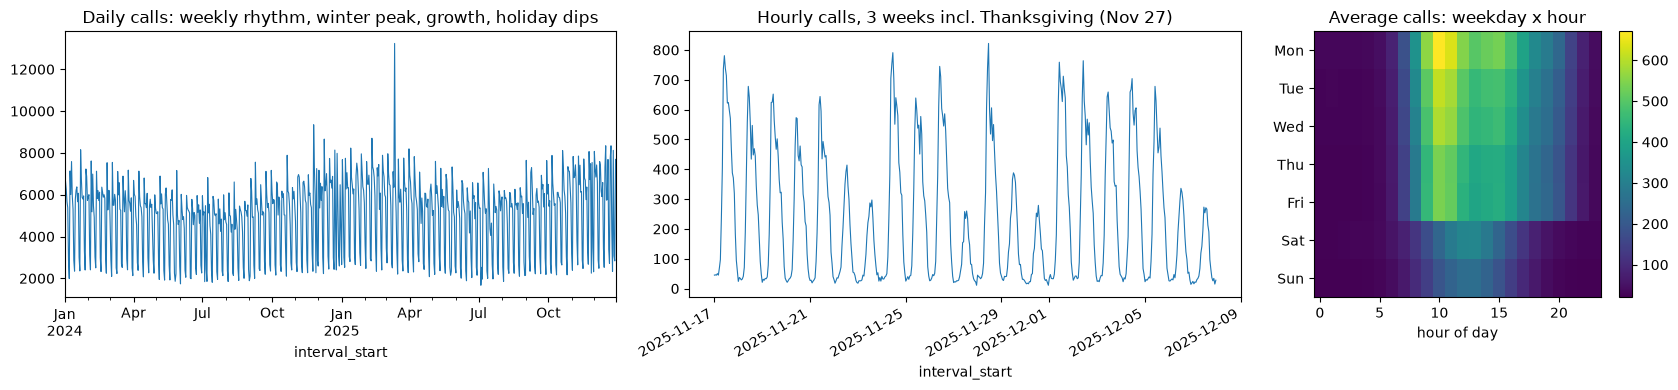

In [3]:
series = raw.drop_duplicates("interval_start").set_index("interval_start")["calls_offered"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4), gridspec_kw={"width_ratios": [2, 2, 1.3]})
series.resample("D").sum().plot(ax=axes[0], lw=0.8)
axes[0].set_title("Daily calls: weekly rhythm, winter peak, growth, holiday dips")
series["2025-11-17":"2025-12-07"].plot(ax=axes[1], lw=0.8)
axes[1].set_title("Hourly calls, 3 weeks incl. Thanksgiving (Nov 27)")
profile = series.groupby([series.index.dayofweek, series.index.hour]).mean().unstack()
im = axes[2].imshow(profile.values, aspect="auto", cmap="viridis")
axes[2].set_yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]); axes[2].set_xlabel("hour of day")
axes[2].set_title("Average calls: weekday x hour"); plt.colorbar(im, ax=axes[2])
plt.tight_layout(); plt.show()

**What we see:**
- A **daily** cycle (period 24 h): nights are almost empty, peaks around 10:00 and 15:00.
- A **weekly** cycle (period 168 h): Monday is the busiest day, weekends are quiet and have a **different intraday shape**.
- **Holidays** look like Sundays, and the next working day gets a catch-up spike.

A single seasonal period (as in classic SARIMA or Holt-Winters) cannot capture both the 24 h and the 168 h cycles on hourly data.
This is exactly the "complex seasonality" case in Hyndman's FPP3 (chapter 12, which uses a bank's call-centre data).

---
## 4. Clean the data: gaps, duplicates and incident spikes

Three typical ACD export problems, and what WFM teams do about them:

| Problem | Why it hurts | Fix |
|---|---|---|
| Duplicated intervals (export retried) | double-counts calls | keep one row per interval |
| Missing intervals | models need a regular hourly grid | fill with the same hour of the previous week (keeps the shape), else interpolate |
| **Incident spikes** (an outage made everyone call) | a one-off event: seasonal models would copy it into next week's forecast | detect with a robust rule and replace with a "normal" value; log it in an incident register |

In [4]:
def clean_acd(export: pd.DataFrame, spike_ratio: float = 2.0, min_excess: float = 100) -> tuple:
    """Return (clean hourly series, table of replaced incident hours)."""
    df = export.drop_duplicates("interval_start", keep="last")              # 1. duplicates
    full_index = pd.date_range(df["interval_start"].min(), df["interval_start"].max(), freq="h")
    y = df.set_index("interval_start")["calls_offered"].reindex(full_index)  # 2. regular grid, gaps = NaN
    n_missing = int(y.isna().sum())
    y = y.fillna(y.shift(168)).interpolate(limit_direction="both")           # same hour last week, else interpolate
    # 3. incidents: far above the median of the same weekly hour in the previous 4 weeks.
    #    Holidays are left out of the reference (a quiet Christmas must not make next week look like a spike).
    flags = day_flags(y.index.normalize().unique(), HOLIDAYS)
    special_hour = (flags[FLAG_COLS].sum(axis=1) > 0).reindex(y.index.normalize()).values
    reference = y.where(~special_hour)
    previous_weeks = pd.concat([reference.shift(168 * k) for k in range(1, 5)], axis=1)
    typical = previous_weeks.median(axis=1).where(previous_weeks.count(axis=1) >= 2)   # need >= 2 normal weeks
    is_spike = (y > spike_ratio * typical) & (y - typical > min_excess)
    incidents = pd.DataFrame({"observed": y[is_spike], "replaced_with": typical[is_spike]})
    y = y.where(~is_spike, typical)
    log.info("removed %d duplicates, filled %d missing hours, replaced %d incident hours",
             len(export) - len(df), n_missing, int(is_spike.sum()))
    return y.rename("calls"), incidents


calls, incident_log = clean_acd(raw)
print("Incident register (hours replaced before modelling):")
incident_log.round(0)

2026-10-21 17:24:41,009 | INFO | removed 5 duplicates, filled 30 missing hours, replaced 6 incident hours


Incident register (hours replaced before modelling):


,observed,replaced_with
2025-03-12 10:00:00,1941.0,716.0
2025-03-12 11:00:00,2073.0,660.0
2025-03-12 12:00:00,1521.0,562.0
2025-03-12 13:00:00,1527.0,504.0
2025-03-12 14:00:00,1377.0,510.0
2025-03-12 15:00:00,1548.0,567.0


Note that we **keep a record** of what was replaced. The incident hours really happened (the agents really had to take
those calls), so reports about the past use the raw data; only the *forecasting* input is cleaned. Holiday dips are **not**
treated as incidents: they repeat every year and the models will handle them with calendar flags.

---
## 5. Validate the data

In [5]:
def validate_hourly(y: pd.Series, min_days: int = 400) -> None:
    """Data contract for the forecasting input."""
    if not isinstance(y.index, pd.DatetimeIndex) or y.index.freq is None or y.index.freqstr != "h":
        raise ValueError("index must be a regular hourly DatetimeIndex")
    if y.isna().any():
        raise ValueError("series still has gaps")
    if (y < 0).any():
        raise ValueError("negative call counts")
    if len(y) < min_days * 24:
        raise ValueError(f"need at least {min_days} days of history, got {len(y) / 24:.0f}")
    log.info("Data contract passed: %d hours (%.0f days)", len(y), len(y) / 24)


validate_hourly(calls)
try:
    validate_hourly(calls.iloc[::2])                    # every second hour: not a regular hourly series anymore
except ValueError as err:
    print("Validation caught a problem ->", err)

2026-10-21 17:24:41,070 | INFO | Data contract passed: 17520 hours (730 days)


Validation caught a problem -> index must be a regular hourly DatetimeIndex


---
## 6. Decompose the series with MSTL (multiple seasonality)

**MSTL** (Bandara, Hyndman & Bergmeir, 2021; in `statsmodels.tsa.seasonal`) repeats STL decomposition once per
seasonal period. With `periods=(24, 168)` it splits the series into:

`calls = trend + daily seasonality + weekly seasonality + remainder`

We decompose `log(1 + calls)`: on the log scale the seasonal effects are **multiplicative** (the 10:00 peak is "x3", not
"+300"), which is what call data looks like when the level grows.

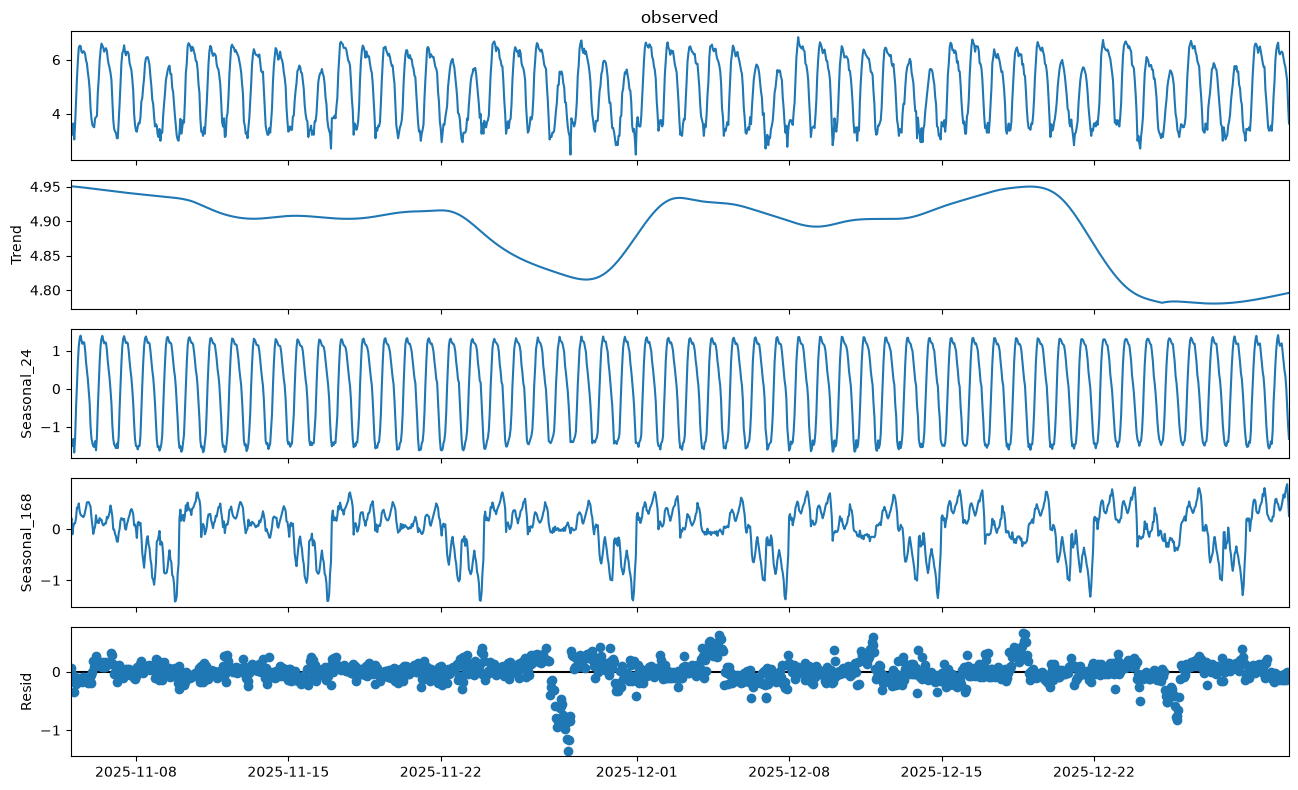

In [6]:
recent = np.log1p(calls[-24 * 7 * 8:])                    # last 8 weeks
decomp = MSTL(recent, periods=(24, 168)).fit()
fig = decomp.plot(); fig.set_size_inches(13, 8); fig.tight_layout(); plt.show()

The plot shows a smooth **trend**, a stable **24 h** pattern, a **168 h** pattern that adds the weekday/weekend
differences, and a **residual** that still contains holiday effects (the dips). The two forecasting models below handle
those holidays explicitly.

---
## 7. Backtesting design, baselines and metrics

### Rolling-origin backtest
We go back to **8 past forecast dates**, 14 days apart, and on each one forecast the next 336 hours using only the
data before it. The first 4 origins (September-November) are "normal" weeks; the last 4 (November-December) contain
Veterans Day, **Thanksgiving**, **Christmas** and New Year's Eve, the hardest period of the year for a WFM team.
We report both periods separately, because an average would hide the holiday problem.

### Baselines used by real WFM tools
- **Seasonal naive (weekly)**: each hour = the same hour one week earlier.
- **4-week average**: each hour = the average of the same weekly hour over the last 4 weeks (smoother; very common).

### Metrics
- **WAPE** (sum of absolute errors / sum of calls), **bias** (positive = over-forecast = overstaffing).
- **MASE**: MAE divided by the in-sample MAE of the weekly seasonal naive. MASE < 1 means better than that naive method.
- Both at **hourly** level (what staffing needs) and **daily** level (what the budget needs).

In [7]:
DATA_END = calls.index[-1]                                                # 2025-12-30 23:00
ORIGINS = [DATA_END - pd.Timedelta(hours=H * k) for k in range(CFG.n_folds, 0, -1)]   # last hour we may see
CALIBRATION_ORIGINS, EVALUATION_ORIGINS = ORIGINS[:4], ORIGINS[4:]
print("Forecast origins (last known hour):")
for o in ORIGINS:
    print(f"  {o}  -> forecasts {o + pd.Timedelta(hours=1):%Y-%m-%d} .. {o + pd.Timedelta(hours=H):%Y-%m-%d}")


def future_index(origin: pd.Timestamp) -> pd.DatetimeIndex:
    return pd.date_range(origin + pd.Timedelta(hours=1), periods=H, freq="h")


def baseline_seasonal_naive(history: pd.Series, origin: pd.Timestamp) -> pd.Series:
    """Repeat the last observed week (336 hours = last week twice)."""
    last_week = history[-168:].values
    return pd.Series(np.tile(last_week, H // 168), index=future_index(origin))


def baseline_4week_average(history: pd.Series, origin: pd.Timestamp) -> pd.Series:
    """Average of the same weekly hour over the last 4 weeks."""
    weeks = history[-168 * 4:].values.reshape(4, 168).mean(axis=0)
    return pd.Series(np.tile(weeks, H // 168), index=future_index(origin))


def accuracy(actual: pd.Series, forecast: pd.Series, scale: float) -> dict:
    err = forecast - actual
    return {"WAPE": err.abs().sum() / actual.sum(), "bias": err.sum() / actual.sum(), "MASE": err.abs().mean() / scale}

Forecast origins (last known hour):
  2025-09-09 23:00:00  -> forecasts 2025-09-10 .. 2025-09-23
  2025-09-23 23:00:00  -> forecasts 2025-09-24 .. 2025-10-07
  2025-10-07 23:00:00  -> forecasts 2025-10-08 .. 2025-10-21
  2025-10-21 23:00:00  -> forecasts 2025-10-22 .. 2025-11-04
  2025-11-04 23:00:00  -> forecasts 2025-11-05 .. 2025-11-18
  2025-11-18 23:00:00  -> forecasts 2025-11-19 .. 2025-12-02
  2025-12-02 23:00:00  -> forecasts 2025-12-03 .. 2025-12-16
  2025-12-16 23:00:00  -> forecasts 2025-12-17 .. 2025-12-30


---
## 8. Model A: hourly MSTL + exponential smoothing + holiday factors

This is the method that `statsforecast.models.MSTL` (Nixtla) implements, written out in a few lines so you can see each step:

1. **Holiday factors**: from past data only, measure how much each kind of day differs from normal
   (e.g. "a major holiday has 35% of a normal day's calls"): ratio of the day's total to the average of the same
   weekday one week before and after.
2. **Holiday-adjust the history**: divide those days by their factor, so the seasonal patterns are learned from normal days.
3. **Decompose** the last 12 weeks of `log(1 + calls)` with MSTL.
4. **Seasonal parts** are forecast by repeating their last week; the **trend + remainder** (the "level") is forecast with
   simple exponential smoothing (an ETS model).
5. Transform back and **multiply by the holiday factors** of the future days.

> **A real trap we hit while building this notebook.** Our first version let statsmodels *optimise* the smoothing
> parameter alpha, which is the default everywhere. Alpha is optimised for **one-step-ahead** errors, so it became large and the
> level followed the **last few hours** before the forecast origin (always a Tuesday night). Every 14-day forecast then
> inherited that night's random wiggle, giving a systematic bias of about +5%. Our horizon is **336 steps**, not one, so we
> need a slow, stable level: we fixed `alpha = 0.01` (a memory of roughly 100 hours), choosing it on the 4 **calibration**
> origins only, so the holiday-season evaluation stays honest. Both versions are kept in the backtest so you can see the difference.

In [8]:
def estimate_day_factors(daily: pd.Series, flags: pd.DataFrame) -> dict:
    """For each special-day flag: median ratio of the day's calls to the same weekday one week before/after."""
    normal = flags[FLAG_COLS].sum(axis=1) == 0
    factors = {}
    for col in FLAG_COLS:
        ratios = []
        for day in flags.index[flags[col] == 1]:
            neighbours = [day - pd.Timedelta(days=7), day + pd.Timedelta(days=7)]
            neighbours = [d for d in neighbours if d in daily.index and normal.get(d, False)]
            if neighbours and day in daily.index:
                ratios.append(daily[day] / np.mean([daily[d] for d in neighbours]))
        factors[col] = float(np.median(ratios)) if ratios else 1.0
    return factors


def day_multiplier(index: pd.DatetimeIndex, factors: dict) -> np.ndarray:
    """Multiplicative calendar effect for every hour in `index`."""
    flags = day_flags(index.normalize().unique(), HOLIDAYS)
    per_day = np.ones(len(flags))
    for col in FLAG_COLS:
        per_day *= np.where(flags[col] == 1, factors[col], 1.0)
    return pd.Series(per_day, index=flags.index).reindex(index.normalize()).values


def forecast_mstl_ets(history: pd.Series, origin: pd.Timestamp, factors: dict, alpha=CFG.level_alpha) -> pd.Series:
    """Model A: hourly MSTL decomposition + exponential smoothing of the level, with holiday factors.
    alpha=None lets statsmodels optimise the smoothing parameter (one-step-ahead), a number fixes it."""
    train = history[-24 * 7 * CFG.hourly_train_weeks:]
    adjusted = np.log1p(train / day_multiplier(train.index, factors))       # holiday-adjusted, log scale
    parts = MSTL(adjusted, periods=(24, 168)).fit()
    seasonal = (parts.seasonal["seasonal_24"] + parts.seasonal["seasonal_168"]).values
    seasonal_future = np.tile(seasonal[-168:], H // 168)                     # repeat the last week
    deseasonalised = (parts.trend + parts.resid).values
    ets = ExponentialSmoothing(deseasonalised, trend=None)
    ets = ets.fit() if alpha is None else ets.fit(smoothing_level=alpha, optimized=False)
    level_future = ets.forecast(H)
    idx = future_index(origin)
    return pd.Series(np.expm1(level_future + seasonal_future).clip(min=0) * day_multiplier(idx, factors), index=idx)


daily_calls = calls.resample("D").sum()
ALL_FLAGS = day_flags(pd.date_range("2024-01-01", "2026-12-31"), HOLIDAYS)
example_factors = estimate_day_factors(daily_calls[:ORIGINS[0]], ALL_FLAGS.loc[:ORIGINS[0]])
print("Calendar factors learned from data before the first origin:", {k: round(v, 2) for k, v in example_factors.items()})

Calendar factors learned from data before the first origin: {'holiday_major': 0.37, 'holiday_minor': 0.85, 'after_holiday': 1.21, 'eve': 0.68}


The learned factors make business sense: a major holiday has roughly a third of the normal volume, the next working day
gets a catch-up of around +20-25%, and Dec 24/31 are quieter. (The simulator's hidden truth was 0.35, 0.85, 1.25 and 0.65,
so the estimation recovers it well.)

---
## 9. Model B: daily SARIMAX with holiday regressors, split into hours

A second, independent approach that many WFM teams use:

1. Forecast the **daily total** with a seasonal ARIMA, `SARIMAX(1,0,1)(0,1,1)_7` on `log(daily calls)`, where the
   calendar flags enter as **regressors** (this is "regression with ARIMA errors", FPP3 chapter 10). The weekly
   differencing (`D=1`, period 7) handles the weekday pattern.
2. Split each day into hours with an **intraday profile**: the average share of each hour for that weekday over the last
   8 normal weeks (holidays use the Sunday profile, because they behave like Sundays).

A nice bonus: SARIMAX gives **prediction intervals** for the daily total from its statistical model.

In [9]:
def intraday_profiles(history: pd.Series, flags: pd.DataFrame, weeks: int = 8) -> pd.DataFrame:
    """Share of the daily volume in each hour, per weekday (rows: weekday 0-6, columns: hour 0-23)."""
    recent = history[-24 * 7 * weeks:]
    day = recent.index.normalize()
    normal_day = (flags.reindex(day)[FLAG_COLS].sum(axis=1) == 0).values
    recent = recent[normal_day]
    share = recent / recent.groupby(recent.index.normalize()).transform("sum")
    return share.groupby([share.index.dayofweek, share.index.hour]).mean().unstack()


def forecast_daily_sarimax(history: pd.Series, origin: pd.Timestamp) -> tuple:
    """Model B: returns (hourly forecast, daily forecast table with 80% and 95% intervals)."""
    daily = history.resample("D").sum()[-CFG.daily_train_days:]
    exog = ALL_FLAGS.loc[daily.index, FLAG_COLS]
    fit = SARIMAX(np.log(daily), exog=exog, order=(1, 0, 1), seasonal_order=(0, 1, 1, 7)).fit(disp=False)
    future_days = pd.date_range(origin.normalize() + pd.Timedelta(days=1), periods=CFG.horizon_days, freq="D")
    fc = fit.get_forecast(CFG.horizon_days, exog=ALL_FLAGS.loc[future_days, FLAG_COLS])
    daily_fc = pd.DataFrame({"forecast": np.exp(fc.predicted_mean.values)}, index=future_days)
    for level in (0.80, 0.95):
        ci = np.exp(fc.conf_int(alpha=1 - level).values)
        daily_fc[f"lo{int(level * 100)}"], daily_fc[f"hi{int(level * 100)}"] = ci[:, 0], ci[:, 1]
    profiles = intraday_profiles(history, ALL_FLAGS)
    idx = future_index(origin)
    weekday = np.where(ALL_FLAGS.loc[idx.normalize(), "holiday_major"].values == 1, 6, idx.dayofweek)  # holiday -> Sunday
    hourly = daily_fc["forecast"].reindex(idx.normalize()).values * profiles.values[weekday, idx.hour]
    return pd.Series(hourly, index=idx), daily_fc


start = time.time()
_, demo_daily = forecast_daily_sarimax(calls[:ORIGINS[-1]], ORIGINS[-1])
print(f"SARIMAX fit + forecast in {time.time() - start:.1f}s. Daily forecast for the Christmas fortnight:")
demo_daily.round(0).head(10)

SARIMAX fit + forecast in 5.4s. Daily forecast for the Christmas fortnight:


,forecast,lo80,hi80,lo95,hi95
2025-12-17,6829.0,6191.0,7534.0,5877.0,7936.0
2025-12-18,6393.0,5794.0,7055.0,5499.0,7433.0
2025-12-19,6326.0,5731.0,6983.0,5439.0,7357.0
2025-12-20,3235.0,2930.0,3572.0,2781.0,3764.0
2025-12-21,2494.0,2259.0,2754.0,2143.0,2903.0
2025-12-22,7913.0,7164.0,8740.0,6797.0,9212.0
2025-12-23,7358.0,6661.0,8129.0,6319.0,8569.0
2025-12-24,4423.0,3992.0,4901.0,3782.0,5174.0
2025-12-25,2207.0,1992.0,2446.0,1886.0,2583.0
2025-12-26,7603.0,6859.0,8427.0,6495.0,8898.0


---
## 10. Reconciliation: make daily and hourly forecasts agree

We now have two forecasts of the same thing at two levels:
- Model A forecasts **hours**; summing them gives a daily total (**bottom-up**).
- Model B forecasts **days**; the intraday profile splits them into hours (**top-down**).

Their daily totals will disagree. Planners need **one coherent set of numbers**: the hourly schedule must add up to the
daily total in the budget. Simple, robust options (see FPP3 chapter 11 on hierarchical forecasting):

| Option | How |
|---|---|
| bottom-up | trust the hourly model, sum it |
| top-down | trust the daily model, split by profile |
| **combination** | average the two hourly forecasts; because each one is coherent, the average is coherent too |

Forecast combination is one of the most reliable tricks in forecasting (many of the best entries in the M4 competition were combinations):
two reasonable models usually make **different** mistakes, and averaging cancels part of them. We test all three.

In [10]:
def run_backtest(calls: pd.Series, origins: list) -> tuple:
    """Return (hourly results, daily SARIMAX results) for every origin."""
    hourly_rows, daily_rows = [], []
    for origin in origins:
        start = time.time()
        history = calls[:origin]                                              # nothing after the origin
        idx = future_index(origin)
        factors = estimate_day_factors(history.resample("D").sum(), ALL_FLAGS.loc[:origin])
        fc = pd.DataFrame({"actual": calls.reindex(idx)}, index=idx)
        fc["seasonal_naive"] = baseline_seasonal_naive(history, origin)
        fc["avg_4_weeks"] = baseline_4week_average(history, origin)
        fc["A_mstl_ets_auto_alpha"] = forecast_mstl_ets(history, origin, factors, alpha=None)
        fc["A_mstl_ets"] = forecast_mstl_ets(history, origin, factors)
        fc["B_sarimax_topdown"], daily_fc = forecast_daily_sarimax(history, origin)
        fc["combination"] = (fc["A_mstl_ets"] + fc["B_sarimax_topdown"]) / 2
        fc["origin"] = origin
        fc["mase_scale"] = history[-24 * 7 * 12:].diff(168).abs().mean()      # in-sample weekly naive MAE
        hourly_rows.append(fc)
        daily_fc["actual"] = calls.resample("D").sum().reindex(daily_fc.index)
        daily_rows.append(daily_fc.assign(origin=origin))
        log.info("origin %s done in %.0fs", origin.date(), time.time() - start)
    return pd.concat(hourly_rows), pd.concat(daily_rows)


backtest, daily_backtest = run_backtest(calls, ORIGINS)
METHODS = ["seasonal_naive", "avg_4_weeks", "A_mstl_ets_auto_alpha", "A_mstl_ets", "B_sarimax_topdown", "combination"]
backtest["period"] = np.where(backtest["origin"].isin(CALIBRATION_ORIGINS), "normal (Sep-Nov)", "holiday season (Nov-Dec)")
print(f"{len(backtest):,} hourly forecasts scored")

2026-10-21 17:25:03,573 | INFO | origin 2025-09-09 done in 12s


2026-10-21 17:25:14,579 | INFO | origin 2025-09-23 done in 11s


2026-10-21 17:25:27,218 | INFO | origin 2025-10-07 done in 13s


2026-10-21 17:25:37,970 | INFO | origin 2025-10-21 done in 11s


2026-10-21 17:25:52,763 | INFO | origin 2025-11-04 done in 15s


2026-10-21 17:26:05,035 | INFO | origin 2025-11-18 done in 12s


2026-10-21 17:26:16,446 | INFO | origin 2025-12-02 done in 11s


2026-10-21 17:26:32,031 | INFO | origin 2025-12-16 done in 16s


2,688 hourly forecasts scored


---
## 11. Backtest results

In [11]:
def score_table(df: pd.DataFrame) -> pd.DataFrame:
    rows = {}
    for m in METHODS:
        per_origin = [accuracy(g["actual"], g[m], g["mase_scale"].iloc[0]) for _, g in df.groupby("origin")]
        hourly = pd.DataFrame(per_origin).mean()
        d = df.groupby(df.index.normalize())[["actual", m]].sum()               # same forecasts, daily totals
        rows[m] = {"hourly WAPE": hourly["WAPE"], "hourly bias": hourly["bias"], "hourly MASE": hourly["MASE"],
                   "daily WAPE": (d[m] - d["actual"]).abs().sum() / d["actual"].sum()}
    return pd.DataFrame(rows).T.round(3)


for period, part in backtest.groupby("period", sort=False):
    print(f"\n=== {period}: {part['origin'].nunique()} origins x 14 days ===")
    display(score_table(part))


=== normal (Sep-Nov): 4 origins x 14 days ===


,hourly WAPE,hourly bias,hourly MASE,daily WAPE
seasonal_naive,0.120,0.005,0.874,0.081
avg_4_weeks,0.110,-0.040,0.798,0.083
A_mstl_ets_auto_alpha,0.134,0.046,0.971,0.108
A_mstl_ets,0.106,-0.002,0.772,0.071
B_sarimax_topdown,0.090,-0.021,0.655,0.059
combination,0.094,-0.011,0.684,0.063



=== holiday season (Nov-Dec): 4 origins x 14 days ===


,hourly WAPE,hourly bias,hourly MASE,daily WAPE
seasonal_naive,0.166,-0.009,1.323,0.132
avg_4_weeks,0.142,-0.018,1.119,0.118
A_mstl_ets_auto_alpha,0.123,0.012,0.973,0.089
A_mstl_ets,0.109,-0.028,0.872,0.071
B_sarimax_topdown,0.097,-0.037,0.775,0.072
combination,0.099,-0.032,0.791,0.070


**How to read these tables:**
- In **normal weeks** the 4-week average (hourly WAPE 0.110) beats seasonal naive (0.120): averaging 4 weeks removes noise.
  Model A with the *auto-optimised* alpha (0.134) is **worse than both baselines**, with a +4.6% bias: the trap described
  in section 8. With the slow, fixed alpha, Model A (0.106) only just beats the 4-week average.
- The clear winner is **Model B** (daily SARIMAX + intraday profile): 0.090 in normal weeks, 0.097 in the holiday season.
  Daily totals are much less noisy than single hours, so the daily model estimates the level better, and the profile
  splits it reliably. "More granular" is not automatically "more accurate".
- In the **holiday season** the baselines fall apart (0.142 and 0.166): they do not know Thanksgiving is coming, and
  *after* a holiday they copy the holiday dip into the next week. The calendar-aware models stay around 0.10-0.11.
  This is where most of the business value of a forecasting model sits.
- The **combination** (0.094 / 0.099) is slightly worse than B alone but better than A. Here B is simply the better model,
  so averaging in A costs a little accuracy. Many teams still deploy the combination because it is less likely to fail badly
  if one model breaks on some future day; deploying B alone is equally defensible. Either way, decide on the
  backtest, not on taste.
- **Daily WAPE** is much lower than hourly WAPE: hourly counts carry random (Poisson) noise that no model can predict.

---
## 12. Error analysis: holidays and hours of the day

Hourly WAPE in the holiday season, special vs normal days:


,seasonal_naive,avg_4_weeks,A_mstl_ets_auto_alpha,A_mstl_ets,B_sarimax_topdown,combination
day_type,,,,,,
normal day,0.139,0.111,0.119,0.108,0.100,0.101
special day,0.412,0.424,0.160,0.121,0.072,0.088


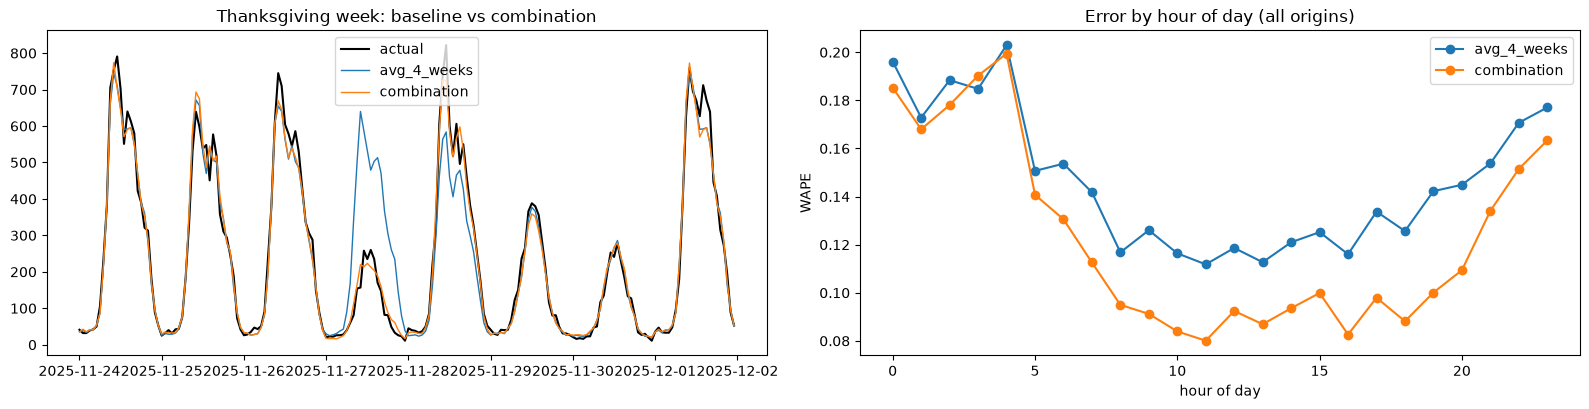

In [12]:
holiday_season = backtest[backtest["period"].str.startswith("holiday")].copy()
special = ALL_FLAGS.reindex(holiday_season.index.normalize())[FLAG_COLS].sum(axis=1).values > 0
holiday_season["day_type"] = np.where(special, "special day", "normal day")
by_type = holiday_season.groupby("day_type").apply(
    lambda g: pd.Series({m: (g[m] - g["actual"]).abs().sum() / g["actual"].sum() for m in METHODS}))
print("Hourly WAPE in the holiday season, special vs normal days:")
display(by_type.round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))
week = holiday_season["2025-11-24":"2025-12-01"]
axes[0].plot(week.index, week["actual"], color="black", lw=1.5, label="actual")
for m in ["avg_4_weeks", "combination"]:
    axes[0].plot(week.index, week[m], lw=1, label=m)
axes[0].set_title("Thanksgiving week: baseline vs combination"); axes[0].legend()
by_hour = backtest.groupby(backtest.index.hour).apply(
    lambda g: pd.Series({m: (g[m] - g["actual"]).abs().sum() / g["actual"].sum() for m in ["avg_4_weeks", "combination"]}))
by_hour.plot(ax=axes[1], marker="o"); axes[1].set_xlabel("hour of day"); axes[1].set_ylabel("WAPE")
axes[1].set_title("Error by hour of day (all origins)")
plt.tight_layout(); plt.show()

- On **special days** the baselines are off by over 40%, while the calendar-aware models stay at 7-12%. Model B is even
  *better* on special days than on normal ones here, because its holiday regressors match how our simulator creates
  holidays exactly; on real data holidays are messier (each one is a bit different). Special days are rare, so a 2-year
  history holds only one or two examples of each: this is why WFM teams keep a hand-maintained list of "events" and
  often apply manual overrides for unusual days.
- **By hour**: the relative error is largest at night (few calls, so a difference of 3 calls is a large percentage) and
  smallest at the peaks. For staffing, the peak hours matter most: they decide how many people are scheduled.

---
## 13. Prediction intervals: are they honest?

A staffing plan needs a range, not just a number ("we expect 520 calls, but it could be 600"). We check two kinds:

1. **Daily SARIMAX intervals** (from the statistical model). An 80% interval should contain the actual value ~80% of the time.
2. **Hourly intervals** for the combination forecast, built with a simple **conformal** method: on the 4 calibration origins
   we measure the log-ratio errors `log((actual+1)/(forecast+1))` per hour of the day and take their 10% and 90%
   quantiles; we then **test** those intervals on the 4 later origins they have never seen.

In [13]:
coverage = []
for period, part in daily_backtest.assign(
        period=np.where(daily_backtest["origin"].isin(CALIBRATION_ORIGINS), "normal (Sep-Nov)", "holiday season (Nov-Dec)")
        ).groupby("period", sort=False):
    for level in (80, 95):
        inside = part["actual"].between(part[f"lo{level}"], part[f"hi{level}"])
        coverage.append({"interval": f"daily SARIMAX {level}%", "period": period, "coverage": inside.mean(), "n_days": len(part)})

def conformal_quantiles(df: pd.DataFrame, method: str, levels=(0.10, 0.80, 0.90)) -> pd.DataFrame:
    """Quantiles of log((actual+1)/(forecast+1)) per hour of day, learned from past backtest errors."""
    log_error = np.log((df["actual"] + 1) / (df[method] + 1))
    return log_error.groupby(df.index.hour).quantile(list(levels)).unstack()      # rows: hour 0-23


def apply_quantile(forecast: pd.Series, q_table: pd.DataFrame, level: float) -> pd.Series:
    """Turn a point forecast into its quantile using the learned error quantiles."""
    return (forecast + 1) * np.exp(q_table[level].reindex(forecast.index.hour).values) - 1


calib = backtest[backtest["origin"].isin(CALIBRATION_ORIGINS)]                   # learn on the first 4 origins only
CONFORMAL_Q = conformal_quantiles(calib, "combination")
evaluation = backtest[backtest["origin"].isin(EVALUATION_ORIGINS)].copy()       # test on the last 4
evaluation["lo80"] = apply_quantile(evaluation["combination"], CONFORMAL_Q, 0.10)
evaluation["hi80"] = apply_quantile(evaluation["combination"], CONFORMAL_Q, 0.90)
inside = evaluation["actual"].between(evaluation["lo80"], evaluation["hi80"])
special_eval = ALL_FLAGS.reindex(evaluation.index.normalize())[FLAG_COLS].sum(axis=1).values > 0
coverage += [{"interval": "hourly conformal 80%", "period": "holiday season, normal days", "coverage": inside[~special_eval].mean(), "n_days": (~special_eval).sum() / 24},
             {"interval": "hourly conformal 80%", "period": "holiday season, special days", "coverage": inside[special_eval].mean(), "n_days": special_eval.sum() / 24}]
pd.DataFrame(coverage).round(3)

,interval,period,coverage,n_days
0,daily SARIMAX 80%,normal (Sep-Nov),0.821,56.0
1,daily SARIMAX 95%,normal (Sep-Nov),0.982,56.0
2,daily SARIMAX 80%,holiday season (Nov-Dec),0.750,56.0
3,daily SARIMAX 95%,holiday season (Nov-Dec),0.893,56.0
4,hourly conformal 80%,"holiday season, normal days",0.744,50.0
5,hourly conformal 80%,"holiday season, special days",0.785,6.0


**Interpretation** (compare each coverage with its nominal level; with only 56 days per period, +/- 5-10 points is noise):
- SARIMAX intervals assume the model is correct and the future behaves like the past. In **normal weeks** they are honest
  (82% for the 80% interval, 98% for the 95% one). In the **holiday season** they **under-cover** (75% and 89%): the model's
  errors are larger there than its formulas assume.
- The conformal hourly 80% intervals, calibrated on normal weeks, cover 74% of hours on the normal days of the holiday
  season and 79% on special days (only 6 days, so very uncertain): a little too narrow, because December is harder than
  September. A practical fix is to calibrate on the same season of the previous year, or to widen the intervals by a
  rule for known difficult periods.
- Lesson: **always measure coverage on a backtest** before you show intervals to a planner. Intervals that are too narrow
  make planners falsely confident; intervals that are too wide make them overstaff "just in case".

---
## 14. From calls to agents: Erlang C

**Erlang C** (A. K. Erlang, 1917; still the core of most WFM software) answers: *given λ calls per hour with an average
handle time AHT, how many agents N do we need to answer X% of calls within T seconds?*

1. **Traffic** in Erlangs: `A = λ x AHT / 3600` (e.g. 400 calls/h x 360 s / 3600 = 40 agents busy on average).
2. **Probability a caller has to wait** with N agents (Erlang C formula, computed here with the numerically stable
   Erlang B recursion `B(n) = A·B(n-1) / (n + A·B(n-1))`, then `C = N·B / (N - A·(1 - B))`).
3. **Service level**: `SL = 1 - C x exp(-(N - A) x T / AHT)`.
4. Increase N until SL >= 80% **and** occupancy `A/N` <= 90%.
5. Divide by `(1 - shrinkage)` to get the number of agents to **schedule** (paid), and round up.

(The `pyworkforce` library implements the same formulas; we write them out so they are easy to read and test.)

In [14]:
def service_level(calls_per_hour: float, agents: int, cfg: Config = CFG) -> float:
    """Share of calls answered within cfg.answer_seconds with `agents` agents on the phones (Erlang C)."""
    traffic = calls_per_hour * cfg.aht_seconds / 3600
    if agents <= traffic:
        return 0.0                                         # queue grows without limit: service collapses
    erlang_b = 1.0
    for n in range(1, agents + 1):                         # Erlang B recursion (no huge factorials)
        erlang_b = traffic * erlang_b / (n + traffic * erlang_b)
    p_wait = agents * erlang_b / (agents - traffic * (1 - erlang_b))   # Erlang C: probability of waiting
    return 1 - p_wait * np.exp(-(agents - traffic) * cfg.answer_seconds / cfg.aht_seconds)


@lru_cache(maxsize=None)                                   # the same call volume always needs the same answer
def agents_on_phones(calls_per_hour: int, cfg: Config = CFG) -> int:
    """Smallest number of productive agents meeting the service-level and occupancy targets."""
    traffic = calls_per_hour * cfg.aht_seconds / 3600
    n = max(cfg.min_agents, int(np.ceil(traffic)))
    while service_level(calls_per_hour, n, cfg) < cfg.target_service_level or traffic / n > cfg.max_occupancy:
        n += 1
    return n


def agents_to_schedule(calls_per_hour: float, cfg: Config = CFG) -> int:
    """Paid agents = productive agents / (1 - shrinkage), rounded up."""
    return int(np.ceil(agents_on_phones(int(np.ceil(calls_per_hour)), cfg) / (1 - cfg.shrinkage)))


example = pd.DataFrame({"calls_per_hour": [20, 100, 400, 700]})
example["traffic_erlangs"] = example["calls_per_hour"] * CFG.aht_seconds / 3600
example["agents_on_phones"] = example["calls_per_hour"].map(agents_on_phones)
example["occupancy"] = (example["traffic_erlangs"] / example["agents_on_phones"]).round(2)
example["service_level"] = [round(service_level(c, n), 3) for c, n in zip(example["calls_per_hour"], example["agents_on_phones"])]
example["agents_to_schedule"] = example["calls_per_hour"].map(agents_to_schedule)
example

,calls_per_hour,traffic_erlangs,agents_on_phones,occupancy,service_level,agents_to_schedule
0,20,2.0,4,0.50,0.844,6
1,100,10.0,14,0.71,0.861,20
2,400,40.0,46,0.87,0.810,66
3,700,70.0,78,0.90,0.835,112


Notice the **economy of scale**: 20 calls/hour need far more agents *per call* than 700 calls/hour (look at occupancy).
Big queues are more efficient, which is why companies merge small teams into large pools. It also means forecast errors at
low-volume night hours cost little, while errors at the peaks decide most of the staffing cost.

---
## 15. Does a better forecast give better staffing?

For each hour of the 4 evaluation origins (the holiday season), we schedule agents from each forecast, then let the
**actual** calls arrive and compute the service level we would have achieved. Two ways to use each forecast:

- **@ point**: staff exactly for the forecast. Even a perfect *unbiased* forecast is too low in about half of the hours.
- **@ P80**: staff for that method's own 80th percentile, learned (conformal, as in section 13) from **its** errors on the
  calibration origins. A more accurate method has narrower errors, so it needs a **smaller safety margin**.

We also add the **perfect forecast** (staffing with the actual calls): the best possible, impossible in practice.

In [15]:
@lru_cache(maxsize=None)
def achieved_service_level(actual_calls: int, scheduled_agents: int) -> float:
    on_phones = int(np.floor(scheduled_agents * (1 - CFG.shrinkage)))
    return service_level(actual_calls, on_phones)


STAFFING_METHODS = ["seasonal_naive", "avg_4_weeks", "A_mstl_ets", "B_sarimax_topdown", "combination"]
staffing_inputs = {}
for m in STAFFING_METHODS:
    staffing_inputs[f"{m} @ point"] = evaluation[m]
    staffing_inputs[f"{m} @ P80"] = apply_quantile(evaluation[m], conformal_quantiles(calib, m, levels=(0.80,)), 0.80)
staffing_inputs["perfect forecast"] = evaluation["actual"]
actual_int = evaluation["actual"].round().astype(int).values
rows = []
for name, forecast in staffing_inputs.items():
    scheduled = np.array([agents_to_schedule(max(f, 0)) for f in forecast.values])
    sl = np.array([achieved_service_level(int(a), int(s)) for a, s in zip(actual_int, scheduled)])
    weighted_sl = (sl * actual_int).sum() / actual_int.sum()                      # weighted by calls
    rows.append({"forecast used": name, "hours meeting 80/20": (sl >= CFG.target_service_level).mean(),
                 "call-weighted service level": weighted_sl, "paid agent-hours": scheduled.sum(),
                 "cost_$": scheduled.sum() * CFG.cost_per_agent_hour})
staffing = pd.DataFrame(rows).set_index("forecast used").sort_index()
staffing["extra cost vs perfect_$"] = staffing["cost_$"] - staffing.loc["perfect forecast", "cost_$"]
staffing.round(3)

,hours meeting 80/20,call-weighted service level,paid agent-hours,cost_$,extra cost vs perfect_$
forecast used,,,,,
A_mstl_ets @ P80,0.793,0.805,59070,1890240.0,121728.0
A_mstl_ets @ point,0.542,0.608,54057,1729824.0,-38688.0
B_sarimax_topdown @ P80,0.827,0.831,59049,1889568.0,121056.0
B_sarimax_topdown @ point,0.531,0.598,53610,1715520.0,-52992.0
avg_4_weeks @ P80,0.822,0.824,61546,1969472.0,200960.0
avg_4_weeks @ point,0.531,0.559,54482,1743424.0,-25088.0
combination @ P80,0.816,0.818,58891,1884512.0,116000.0
combination @ point,0.538,0.607,53835,1722720.0,-45792.0
perfect forecast,0.993,0.833,55266,1768512.0,0.0


**Reading the staffing table** (the business view of the forecast):
- The **perfect forecast** meets 80/20 in 99% of hours (not 100%: staff come in whole people). Its call-weighted service
  level is 83%, just above target, because Erlang C adds exactly enough agents and no more.
- **Every method staffed "@ point" fails**: only 53-56% of hours meet 80/20, and they look *cheaper* than perfect.
  That is not a saving: in every hour where the actual calls exceed the forecast (about half of them) the service collapses.
  Staffing to a point forecast is the most common beginner mistake in WFM.
- Staffed **@ P80**, all methods reach roughly 79-83% of hours, so now the costs are comparable. The calendar-aware models
  (A, B, combination: about $1.88-1.89M) are about **$65-85k cheaper** over these 8 weeks than the baselines
  (about $1.96-1.97M) at a similar service level. Their errors are smaller, so their safety margin can be smaller.
  **That** is the money a better forecast is worth.
- Which percentile to staff to is a **business decision** (cost of a missed SLA vs cost of an agent-hour). The forecast's
  job is to make that trade-off visible and honest.

---
## 16. Save the configuration and a forecast-and-staff function

Classical models like these are cheap to fit, so production systems usually **refit them at every run** on the newest
data, rather than loading an old fitted model. What we save is the **recipe**: the config, the calendar rules, the
conformal error quantiles, and (for audit) the last fitted model and its backtest scores.
In a real project: `models/call_forecast/v1/` or a model registry.

In [16]:
ARTIFACT_DIR = Path(tempfile.mkdtemp(prefix="call_forecast_"))           # in real life: models/call_forecast/v1/
bundle = {
    "config": asdict(CFG),
    "major_holidays": sorted(MAJOR_HOLIDAYS),
    "conformal_quantiles": CONFORMAL_Q,
    "method": "combination of MSTL+ETS (hourly) and SARIMAX(1,0,1)(0,1,1)7 with calendar flags (daily, top-down)",
}
with open(ARTIFACT_DIR / "bundle.pkl", "wb") as fh:
    pickle.dump(bundle, fh)
metadata = {"saved_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
            "statsmodels_version": statsmodels.__version__, "data_end": str(DATA_END),
            "backtest_holiday_season": score_table(backtest[backtest["origin"].isin(EVALUATION_ORIGINS)]).to_dict(),
            "config": asdict(CFG)}
(ARTIFACT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2, default=str))
print([f.name for f in ARTIFACT_DIR.iterdir()])

['metadata.json', 'bundle.pkl']


In [17]:
def forecast_and_staff(acd_export: pd.DataFrame, bundle: dict) -> pd.DataFrame:
    """Raw ACD export in -> 14-day hourly forecast, P80 and agents to schedule out."""
    if not {"interval_start", "calls_offered"} <= set(acd_export.columns):
        raise ValueError("export needs columns interval_start and calls_offered")
    if (acd_export["calls_offered"] < 0).any():
        raise ValueError("negative call counts in export")
    y, incidents = clean_acd(acd_export)
    validate_hourly(y)
    if len(incidents) > 48:
        raise ValueError(f"{len(incidents)} incident hours detected: check the export before forecasting")
    origin = y.index[-1]
    factors = estimate_day_factors(y.resample("D").sum(), ALL_FLAGS.loc[:origin])
    hourly_a = forecast_mstl_ets(y, origin, factors)
    hourly_b, _ = forecast_daily_sarimax(y, origin)
    out = pd.DataFrame({"forecast": (hourly_a + hourly_b) / 2})
    out["p80"] = apply_quantile(out["forecast"], bundle["conformal_quantiles"], 0.80)
    out["agents_to_schedule"] = [agents_to_schedule(v) for v in out["forecast"]]
    out["agents_to_schedule_p80"] = [agents_to_schedule(v) for v in out["p80"]]
    return out.round(1)


with open(ARTIFACT_DIR / "bundle.pkl", "rb") as fh:
    loaded_bundle = pickle.load(fh)
start = time.time()
plan = forecast_and_staff(raw, loaded_bundle)
print(f"Forecast for {plan.index[0]} .. {plan.index[-1]} built in {time.time() - start:.0f}s")
print("Paid agent-hours for the next 14 days:", int(plan["agents_to_schedule"].sum()),
      "| with P80 safety margin:", int(plan["agents_to_schedule_p80"].sum()))
plan.loc["2026-01-05 07:00":"2026-01-05 12:00"]

2026-10-21 17:26:37,914 | INFO | removed 5 duplicates, filled 30 missing hours, replaced 6 incident hours


2026-10-21 17:26:37,934 | INFO | Data contract passed: 17520 hours (730 days)


Forecast for 2025-12-31 00:00:00 .. 2026-01-13 23:00:00 built in 20s
Paid agent-hours for the next 14 days: 13412 | with P80 safety margin: 14711


,forecast,p80,agents_to_schedule,agents_to_schedule_p80
2026-01-05 07:00:00,218.0,247.8,39,43
2026-01-05 08:00:00,406.0,440.2,68,73
2026-01-05 09:00:00,653.4,707.5,105,113
2026-01-05 10:00:00,791.1,841.6,126,135
2026-01-05 11:00:00,731.7,802.6,118,129
2026-01-05 12:00:00,635.5,702.8,102,113


In [18]:
# Bad input must be rejected with a clear message
for case, bad in {"negative calls": raw.assign(calls_offered=raw["calls_offered"].where(raw.index != 10, -5)),
                  "too little history": raw.tail(24 * 100),
                  "wrong columns": raw.rename(columns={"calls_offered": "calls"})}.items():
    try:
        forecast_and_staff(bad, loaded_bundle)
        print(f"{case:20s} -> NOT caught (bug!)")
    except ValueError as err:
        print(f"{case:20s} -> rejected: {err}")

negative calls       -> rejected: negative call counts in export


2026-10-21 17:26:57,586 | INFO | removed 0 duplicates, filled 5 missing hours, replaced 0 incident hours


too little history   -> rejected: need at least 400 days of history, got 100
wrong columns        -> rejected: export needs columns interval_start and calls_offered


---
## 17. Automated tests

In [19]:
def test_erlang_c_known_value():
    """Textbook check: 10 Erlangs of traffic with 12 agents -> probability of waiting ~ 0.449."""
    traffic, agents = 10.0, 12
    calls = traffic * 3600 / CFG.aht_seconds
    sl = service_level(calls, agents)
    p_wait = (1 - sl) / np.exp(-(agents - traffic) * CFG.answer_seconds / CFG.aht_seconds)
    assert abs(p_wait - 0.449) < 0.005, p_wait


def test_more_calls_need_more_agents():
    needs = [agents_on_phones(c) for c in range(0, 1000, 50)]
    assert all(a <= b for a, b in zip(needs, needs[1:]))


def test_top_down_is_coherent():
    """Hourly top-down forecast must add up to the daily SARIMAX forecast."""
    hourly, daily = forecast_daily_sarimax(calls[:ORIGINS[0]], ORIGINS[0])
    assert np.allclose(hourly.resample("D").sum().values, daily["forecast"].values, rtol=1e-6)


def test_no_future_data_used():
    """Forecasts made at an origin must not change if the future is replaced by garbage."""
    origin = ORIGINS[0]
    poisoned = calls.copy(); poisoned[origin + pd.Timedelta(hours=1):] = 99_999
    factors = estimate_day_factors(calls[:origin].resample("D").sum(), ALL_FLAGS.loc[:origin])
    a = forecast_mstl_ets(calls[:origin], origin, factors)
    b = forecast_mstl_ets(poisoned[:origin], origin, factors)
    assert np.allclose(a, b)


def test_model_beats_baseline_in_holiday_season():
    table = score_table(backtest[backtest["origin"].isin(EVALUATION_ORIGINS)])
    assert table.loc["combination", "hourly WAPE"] < table.loc["avg_4_weeks", "hourly WAPE"]


for test in [test_erlang_c_known_value, test_more_calls_need_more_agents, test_top_down_is_coherent,
             test_no_future_data_used, test_model_beats_baseline_in_holiday_season]:
    test()
    print(f"PASSED  {test.__name__}")

PASSED  test_erlang_c_known_value
PASSED  test_more_calls_need_more_agents


PASSED  test_top_down_is_coherent


PASSED  test_no_future_data_used


PASSED  test_model_beats_baseline_in_holiday_season


---
## 18. Summary, exercises and resources

| Practice | What we did | Where it is used |
|---|---|---|
| Forecast **offered** calls | ACD export, not answered calls | Every WFM team |
| Cleaning with an incident register | duplicates, gaps (same hour last week), robust spike rule | Keeps one-off events out of the forecast |
| Multiple seasonality | MSTL with periods 24 and 168 | statsmodels, Nixtla `statsforecast` MSTL |
| Calendar effects | learned holiday factors; holiday regressors in SARIMAX | WFM "special days" / event lists |
| Baselines | seasonal naive, 4-week average | What WFM tools do by default |
| Rolling-origin backtest | 8 origins, normal vs holiday period reported separately | FPP3 time series cross-validation |
| Reconciliation & combination | bottom-up, top-down, average | Budget (daily) and schedule (hourly) that agree |
| Interval coverage + conformal | checked, recalibrated on past errors | Honest uncertainty for planners |
| Erlang C staffing | service level, occupancy, shrinkage | Every contact-centre staffing plan |
| Business evaluation | service level achieved vs paid agent-hours | How WFM judges a forecast |

### Practice exercises
1. Change `aht_seconds` to 300 and `target_service_level` to 0.9. How do agent-hours and the value of a better forecast change?
2. Replace the exponential smoothing of the level in Model A with an `ARIMA` on the deseasonalised series, or try
   `alpha` values 0.003 / 0.03 on the calibration origins. How sensitive is the result?
3. Calibrate the conformal intervals separately for special days (you will need the 2024 holiday season as calibration data).
4. Try a weighted combination (e.g. 70% the better model). Is it worth the risk of over-fitting the weight to 8 origins?
5. Add half-hour intervals (`freq="30min"`, periods 48 and 336): most real WFM tools schedule in 15- or 30-minute slots.
6. Erlang C ignores callers who hang up. Read about **Erlang A** (with abandonment) and discuss when C overstaffs.

### Resources (checked)
- Hyndman & Athanasopoulos, *Forecasting: Principles and Practice* (3rd ed.): ch. 12.1 "Complex seasonality" (uses call-centre data) https://otexts.com/fpp3/advanced.html ; ch. 10 dynamic regression https://otexts.com/fpp3/dynamic-regression.html ; ch. 5 time series cross-validation and accuracy https://otexts.com/fpp3/toolbox.html ; ch. 11 reconciliation https://otexts.com/fpp3/hierarchical-forecasting.html
- statsmodels MSTL example notebook: https://www.statsmodels.org/stable/examples/notebooks/generated/mstl_decomposition.html
- Bandara, Hyndman & Bergmeir (2021), *MSTL: A Seasonal-Trend Decomposition Algorithm for Time Series with Multiple Seasonal Patterns*: https://arxiv.org/abs/2107.13462
- Nixtla statsforecast, multiple seasonalities tutorial: https://nixtlaverse.nixtla.io/statsforecast/docs/tutorials/multipleseasonalities.html
- pyworkforce (Erlang C, staffing and scheduling in Python): https://github.com/rodrigo-arenas/pyworkforce
- Erlang C formula background: https://en.wikipedia.org/wiki/Erlang_(unit)#Erlang_C_formula

### Related notebooks in this repo
- Decomposition, STL and stationarity: `01_time_series_basics.ipynb`
- ETS, ARIMA, SARIMAX in depth: `02_classical_methods.ipynb`
- Intervals, conformal prediction and calibration: `09_probabilistic_forecasting.ipynb`
- Hierarchical forecasting (reconciliation): `06_advanced_forecasting.ipynb`
- Companion retail project (LightGBM, many series, orders): `11_industry_retail_demand_forecasting.ipynb`